In [1]:
import autoroot
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib import cm
from matplotlib.colors import Normalize
from plot_config import set_plot_style
# --- Configuration ---
font_size = 40
figsize = (12, 8)
palette = 'coolwarm'

set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette=palette)


# --- Memory function ---
def exp(s, alpha):
    return np.exp(-s/10 /(alpha))

def poly(s, alpha):
    return 1 / (1 + s) ** (1/3 / alpha)

def impulse(s, alpha):
    alpha = np.floor(alpha* (T // 2))
    THRESHOLD = 0.5
    return ((s > alpha - THRESHOLD) & (s < alpha +THRESHOLD))

def airy(s, alpha):
    from scipy import special

    ai, aip, bi, bip = special.airy(40 * (s / T - 0.5 * alpha))

    return ai


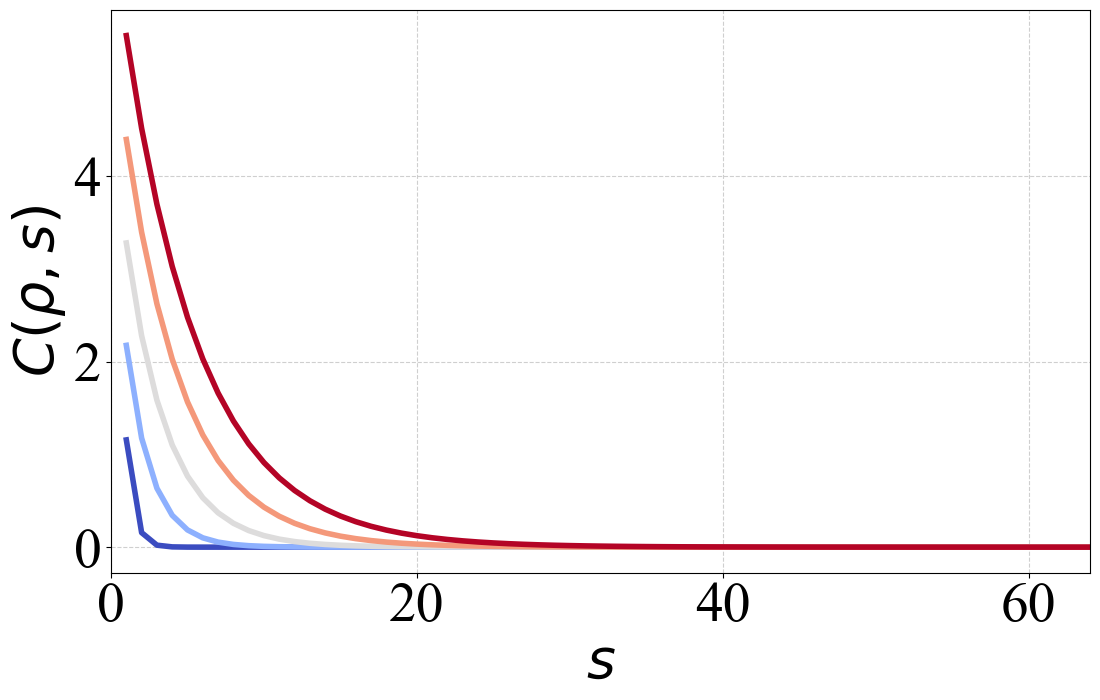

In [2]:

T = 64
s_values = np.arange(1, T+1)
alpha_values = np.linspace(0.1, 1.0, 5)
memory_functions = {
    'Exponential': exp,
    'Polynomial': poly,
    'Impulse': impulse,
    'Airy': airy
}

# --- Cumulative function C(rho, s) ---
def cumulative_function(rho_func, alpha):
    full_range = np.arange(0, T)
    rho_values = np.abs(rho_func(full_range, alpha)) ** 2
    # Apply permutation to make it monotone non-increasing
    pi_indices = np.argsort(-rho_values)  # Sort in descending order
    rho_sorted = rho_values[pi_indices]
    return np.array([np.sum(rho_sorted[s:]) for s in range(T)])

# --- Plotting ---
name = 'Exponential'
func = memory_functions[name]

fig, ax1 = plt.subplots(figsize=figsize)

# Color mapping setup
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm  # Better color scheme
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

for alpha in alpha_values:
    color = cmap(norm(alpha))
    C_values = cumulative_function(func, alpha)
    ax1.plot(s_values, C_values, color=color, linewidth=4)

# Set labels
ax1.set_xlabel(r'$s$', fontsize=font_size)
ax1.set_ylabel(r'$C(\rho,s)$', fontsize=font_size)
ax1.set_xlim(0, 64)
plt.tight_layout()

plt.savefig(f'figs/tcn_complexity_{name}.pdf', bbox_inches='tight')


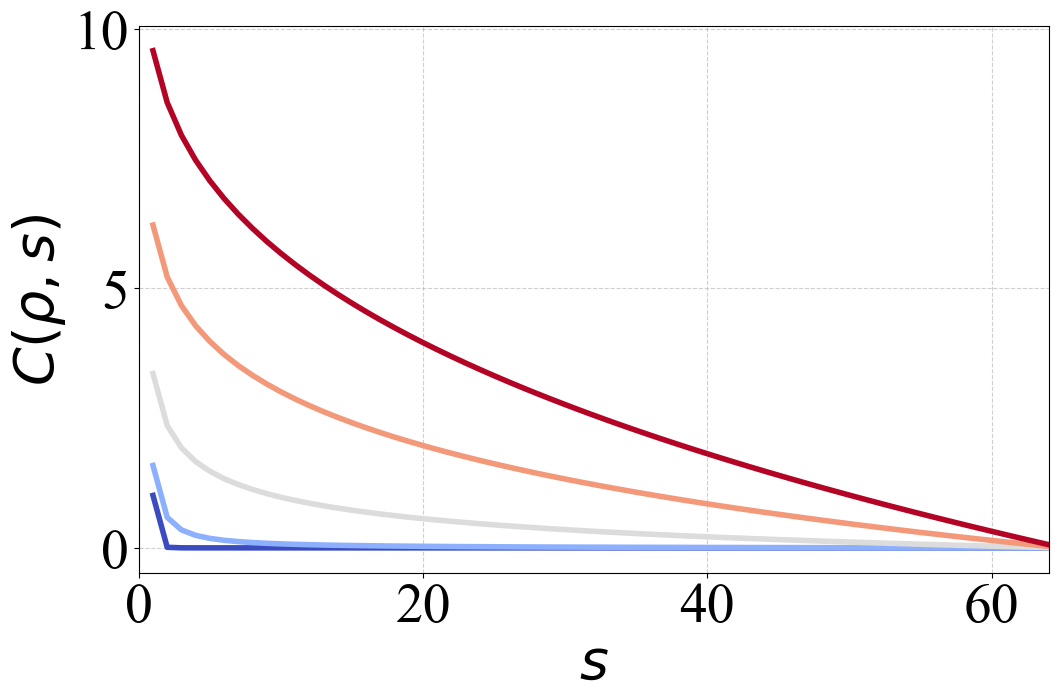

In [3]:
# --- Plotting ---
name = 'Polynomial'
func = memory_functions[name]
alpha_values = np.linspace(0.1, 1.0, 5)
fig, ax1 = plt.subplots(figsize=figsize)

# Color mapping setup
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm  # Better color scheme
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

for alpha in alpha_values:
    color = cmap(norm(alpha))
    C_values = cumulative_function(func, alpha)
    ax1.plot(s_values, C_values, color=color, linewidth=4)

# Set labels
ax1.set_xlabel(r'$s$', fontsize=font_size)
ax1.set_ylabel(r'$C(\rho,s)$', fontsize=font_size)
ax1.set_xlim(0,64)
plt.tight_layout()
plt.savefig(f'figs/tcn_complexity_{name}.pdf', bbox_inches='tight')


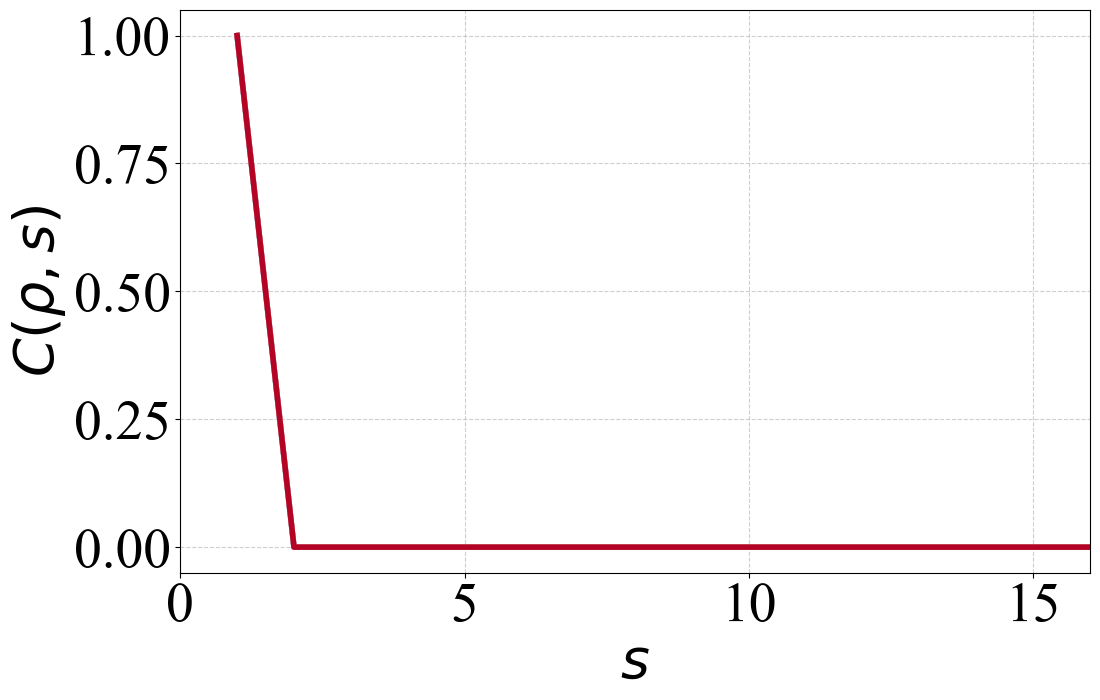

In [4]:
# --- Plotting ---
name = 'Impulse'
func = memory_functions[name]
alpha_values = np.linspace(0,1,5)
fig, ax1 = plt.subplots(figsize=figsize)

# Color mapping setup
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm  # Better color scheme
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

for alpha in alpha_values:
    color = cmap(norm(alpha))
    C_values = cumulative_function(func, alpha)
    ax1.plot(s_values, C_values, color=color, linewidth=4)

# Set labels
ax1.set_xlabel(r'$s$', fontsize=font_size)
ax1.set_ylabel(r'$C(\rho,s)$', fontsize=font_size)
ax1.set_xlim(0,16)

plt.tight_layout()
plt.savefig(f'figs/tcn_complexity_{name}.pdf', bbox_inches='tight')


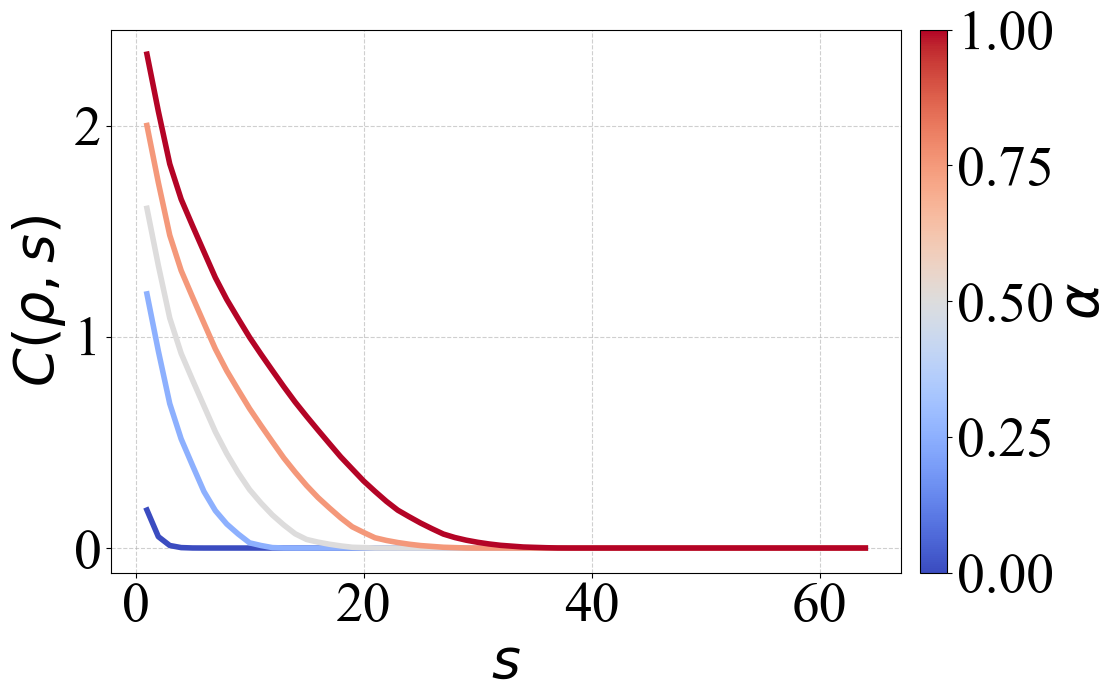

In [5]:
# --- Plotting ---
name = 'Airy'
func = memory_functions[name]

fig, ax1 = plt.subplots(figsize=figsize)

# Color mapping setup
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm  # Better color scheme
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

for alpha in alpha_values:
    color = cmap(norm(alpha))
    C_values = cumulative_function(func, alpha)
    ax1.plot(s_values, C_values, color=color, linewidth=4)

# Set labels
ax1.set_xlabel(r'$s$', fontsize=font_size)
ax1.set_ylabel(r'$C(\rho,s)$', fontsize=font_size)

# Add colorbar
cbar = fig.colorbar(sm, ax=ax1, pad=0.02)
cbar.set_label(r'$\alpha$', size=font_size)
cbar.ax.tick_params(labelsize=font_size)

plt.tight_layout()
plt.savefig(f'figs/tcn_complexity_{name}.pdf', bbox_inches='tight')
